PRACTICE 1: Tính hiệp phương sai (Covariance)  
1. Dữ liệu 2 chiều $(x, y)$

In [ ]:
import numpy as np
import pandas as pd

# Dữ liệu 2 chiều từ đề bài
x1 = [10, 39, 19, 23, 28]
y1 = [43, 13, 32, 21, 20]

# Đưa vào ma trận (mỗi hàng là một biến, hoặc dùng np.vstack)
data_2d = np.vstack([x1, y1])

# Tính ma trận hiệp phương sai (rowvar=True nghĩa là mỗi hàng là một biến)
cov_matrix_2d = np.cov(data_2d)
print("--- Ma trận hiệp phương sai 2 chiều ---")
print(cov_matrix_2d)

# Nhận xét: Giá trị hiệp phương sai giữa x và y là âm (cov < 0),
# chứng tỏ khi x tăng thì y có xu hướng giảm (mối quan hệ nghịch biến).

--- Ma trận hiệp phương sai 2 chiều ---
[[ 115.7  -120.55]
 [-120.55  138.7 ]]


2. Dữ liệu 3 chiều $(x, y, z)$

In [ ]:
# Dữ liệu 3 chiều từ đề bài
x2 = [1, -1, 4]
y2 = [2, 1, 3]
z2 = [1, 3, -1]

data_3d = np.vstack([x2, y2, z2])

cov_matrix_3d = np.cov(data_3d)
print("\n--- Ma trận hiệp phương sai 3 chiều ---")
print(cov_matrix_3d)

# Nhận xét: Ma trận vuông 3x3 thể hiện phương sai của từng biến trên đường chéo chính
# và hiệp phương sai giữa các cặp biến ở các vị trí còn lại.


--- Ma trận hiệp phương sai 3 chiều ---
[[ 6.33333333  2.5        -5.        ]
 [ 2.5         1.         -2.        ]
 [-5.         -2.          4.        ]]


PRACTICE 2 & PRACTICE 3: Phân tích thành phần chính (PCA thủ công & thư viện)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Dữ liệu đề bài (Practice 2)
X_data = np.array([
    [2.5, 2.4],
    [0.5, 0.7],
    [2.2, 2.9],
    [1.9, 2.2],
    [3.1, 3.0],
    [2.3, 2.7],
    [2.0, 1.6],
    [1.0, 1.1],
    [1.5, 1.6],
    [1.1, 0.9]
])

# 2.1 Chuẩn hóa dữ liệu (trừ đi giá trị trung bình của từng cột)
mean_val = np.mean(X_data, axis=0)
X_centered = X_data - mean_val
print("2.1 Dữ liệu đã chuẩn hóa:\n", X_centered)

# 2.2 Tính ma trận hiệp phương sai (rowvar=False vì mỗi cột là một biến)
cov_matrix = np.cov(X_centered, rowvar=False)
print("\n2.2 Ma trận hiệp phương sai:\n", cov_matrix)

# 2.3 Tính vector riêng và giá trị riêng
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
print("\n2.3 Giá trị riêng:\n", eigenvalues)
print("Vector riêng:\n", eigenvectors)

# 2.4 & 2.5 Giảm chiều dữ liệu xuống 1 chiều bằng cách chiếu lên eigenvector tương ứng
# Sắp xếp các giá trị riêng giảm dần để chọn component chính
sorted_idx = np.argsort(eigenvalues)[::-1]
eigenvectors_sorted = eigenvectors[:, sorted_idx]
projected_data = np.dot(X_centered, eigenvectors_sorted)
reduced_data_1d = projected_data[:, 0:1] # Giữ lại 1 chiều
print("\n2.5 Dữ liệu sau khi giảm xuống 1 chiều:\n", reduced_data_1d)

# --- PRACTICE 3: Sử dụng thư viện PCA của sklearn ---
pca = PCA(n_components=1)
X_pca = pca.fit_transform(X_data)
print("\n--- Kết quả dùng thư viện PCA sklearn ---")
print(X_pca)

2.1 Dữ liệu đã chuẩn hóa:
 [[ 0.69  0.49]
 [-1.31 -1.21]
 [ 0.39  0.99]
 [ 0.09  0.29]
 [ 1.29  1.09]
 [ 0.49  0.79]
 [ 0.19 -0.31]
 [-0.81 -0.81]
 [-0.31 -0.31]
 [-0.71 -1.01]]

2.2 Ma trận hiệp phương sai:
 [[0.61655556 0.61544444]
 [0.61544444 0.71655556]]

2.3 Giá trị riêng:
 [0.0490834  1.28402771]
Vector riêng:
 [[-0.73517866 -0.6778734 ]
 [ 0.6778734  -0.73517866]]

2.5 Dữ liệu sau khi giảm xuống 1 chiều:
 [[-0.82797019]
 [ 1.77758033]
 [-0.99219749]
 [-0.27421042]
 [-1.67580142]
 [-0.9129491 ]
 [ 0.09910944]
 [ 1.14457216]
 [ 0.43804614]
 [ 1.22382056]]

--- Kết quả dùng thư viện PCA sklearn ---
[[ 0.82797019]
 [-1.77758033]
 [ 0.99219749]
 [ 0.27421042]
 [ 1.67580142]
 [ 0.9129491 ]
 [-0.09910944]
 [-1.14457216]
 [-0.43804614]
 [-1.22382056]]


PRACTICE 4: Phân loại rượu (Wine Dataset) bằng PCA và Logistic Regression

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Tải dữ liệu Wine từ UCI repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data"
columns = [
    'Class', 'Alcohol', 'Malic_acid', 'Ash', 'Alcalinity_of_ash', 'Magnesium',
    'Total_phenols', 'Flavanoids', 'Nonflavanoid_phenols', 'Proanthocyanins',
    'Color_intensity', 'Hue', 'OD280_OD315', 'Proline'
]
df = pd.read_csv(url, header=None, names=columns)

# Tách features (X) và labels (y)
X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

# 4.1 Chia tập dữ liệu Train/Test theo tỷ lệ 7:3
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Chuẩn hóa dữ liệu (rất quan trọng cho PCA và Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4.2 & 4.3 Áp dụng PCA và xem tỷ lệ phương sai giải thích được
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Tỷ lệ phương sai giải thích bởi 2 thành phần chính:", pca.explained_variance_ratio_)

# 4.5, 4.6 & 4.7 Huấn luyện mô hình Logistic Regression trên dữ liệu 2 chiều
clf = LogisticRegression(random_state=42)
clf.fit(X_train_pca, y_train)

# Đánh giá trên tập Train và Test
y_train_pred = clf.predict(X_train_pca)
y_test_pred = clf.predict(X_test_pca)

print("Độ chính xác trên tập Train (2D):", accuracy_score(y_train, y_train_pred))
print("Độ chính xác trên tập Test (2D):", accuracy_score(y_test, y_test_pred))

Tỷ lệ phương sai giải thích bởi 2 thành phần chính: [0.36196226 0.18763862]
Độ chính xác trên tập Train (2D): 0.9596774193548387
Độ chính xác trên tập Test (2D): 0.9629629629629629


PRACTICE 5: Phân rã giá trị kỳ dị (SVD) và Nén ảnh

--- Ma trận U ---
[[-0.70710678 -0.70710678]
 [-0.70710678  0.70710678]]
--- Các giá trị kỳ dị S ---
[5. 3.]
--- Ma trận V chuyển vị (Vt) ---
[[-7.07106781e-01 -7.07106781e-01 -6.47932334e-17]
 [-2.35702260e-01  2.35702260e-01 -9.42809042e-01]
 [-6.66666667e-01  6.66666667e-01  3.33333333e-01]]

--- Pseudo inverse của A ---
[[ 0.15555556  0.04444444]
 [ 0.04444444  0.15555556]
 [ 0.22222222 -0.22222222]]


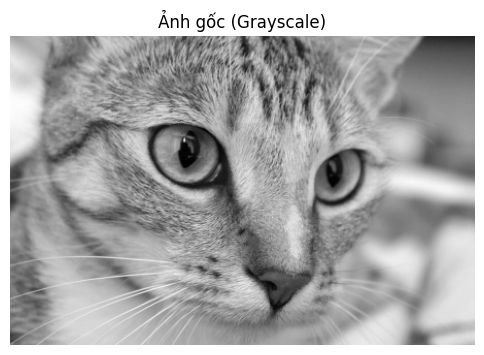

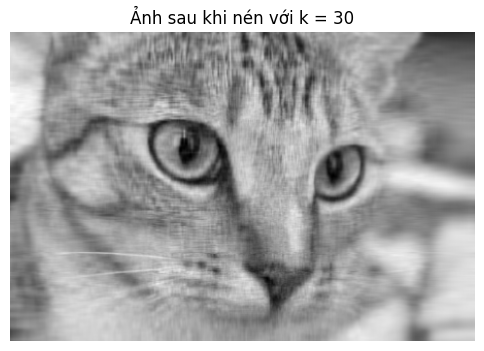

In [ ]:
import numpy as np
from skimage import data
from skimage.color import rgb2gray
from scipy.linalg import svd
import matplotlib.pyplot as plt

# 5.2 Khởi tạo ma trận mẫu cho SVD (theo đề bài)
A = np.array([
    [3, 2, 2],
    [2, 3, -2]
])

# 5.3 Thực hiện SVD cho ma trận A
U, S, Vt = svd(A)
print("--- Ma trận U ---")
print(U)
print("--- Các giá trị kỳ dị S ---")
print(S)
print("--- Ma trận V chuyển vị (Vt) ---")
print(Vt)

# 5.5 Tính Pseudo inverse của A
pinv_A = np.linalg.pinv(A)
print("\n--- Pseudo inverse của A ---")
print(pinv_A)

# 5.6 Lấy hình ảnh mẫu từ thư viện data.chelsea() và chuyển sang ảnh xám
image_rgb = data.chelsea()
image_gray = rgb2gray(image_rgb)

plt.figure(figsize=(6, 6))
plt.imshow(image_gray, cmap='gray')
plt.title("Ảnh gốc (Grayscale)")
plt.axis('off')
plt.show()

# 5.7 Áp dụng SVD để nén ảnh (giữ lại k giá trị kỳ dị hàng đầu, ví dụ k = 30)
U_img, S_img, Vt_img = svd(image_gray)
k = 30
image_compressed = np.dot(U_img[:, :k], np.dot(np.diag(S_img[:k]), Vt_img[:k, :]))

# 5.8 Hiển thị kết quả nén ảnh
plt.figure(figsize=(6, 6))
plt.imshow(image_compressed, cmap='gray')
plt.title(f"Ảnh sau khi nén với k = {k}")
plt.axis('off')
plt.show()

# Nhận xét: Bằng cách giữ lại k thành phần kỳ dị lớn nhất, ta có thể tái tạo lại ảnh
# với dung lượng lưu trữ nhỏ hơn đáng kể nhưng vẫn giữ lại được các đặc trưng hình ảnh chính.